In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import style
style.use('dark_background')
from sklearn.model_selection import KFold
from sklearn.datasets import make_blobs
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV

# Creating Data

In [ ]:
X, y = make_blobs(n_samples = 1000, n_features = 2, centers = 3, cluster_std = 3.5, random_state = 42)
#make_blobs genera datos sintéticos en forma de “manchas” (blobs) que representan clústeres. para clasificacion, clustering ML
#n_samples = 1000. Número total de puntos que se van a generar.
#n_features = Número de características (features) por cada punto → es decir, cuántas columnas tendrá X./var
#centers = 3- mº clusteres que se generan, centros donde se generan grupos de datos
#cluster_std-> desviacion standard de cada cluster
#random_state = 42. Hace que el resultado se repita siempre igual → fija la semilla aleatoria.

In [ ]:
X.shape

(1000, 2)

In [ ]:
np.unique(y)

array([0, 1, 2])

# Visualizing the data

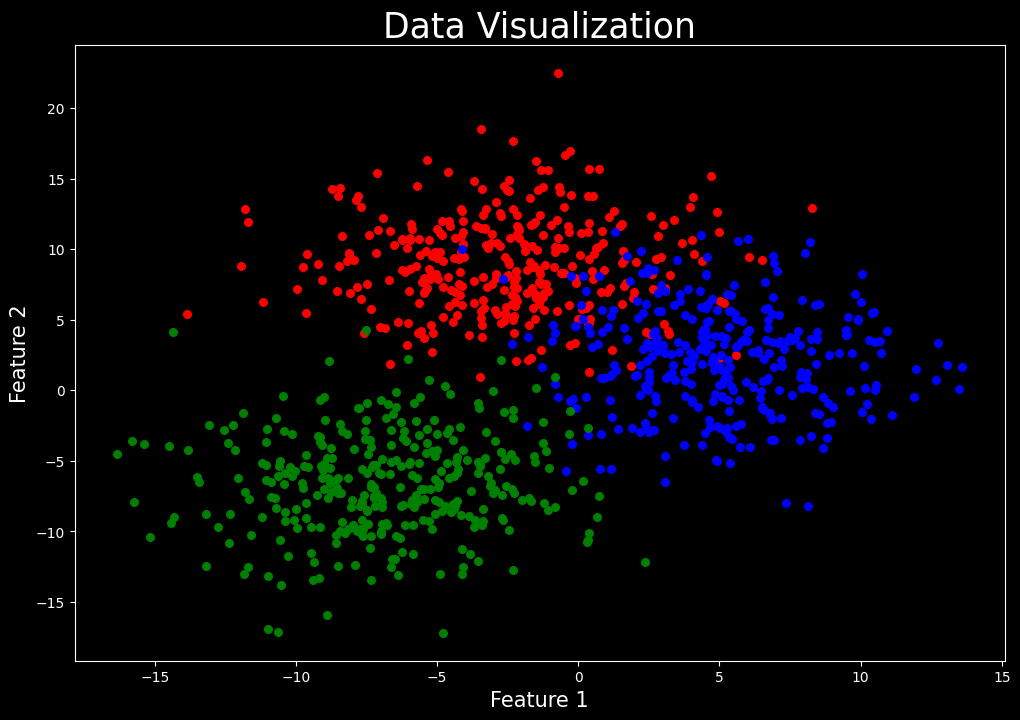

In [ ]:
plt.figure(figsize = (12,8))
plt.scatter(X[y == 0, 0], X[y == 0, 1], s = 30, c = 'red')
plt.scatter(X[y == 1, 0], X[y == 1, 1], s = 30, c = 'blue')
plt.scatter(X[y == 2, 0], X[y == 2, 1], s = 30, c = 'green')
plt.xlabel('Feature 1', fontsize = 15)
plt.ylabel('Feature 2', fontsize = 15)
plt.title('Data Visualization', fontsize = 25)
plt.show()

# Splitting the data into test and train

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

# Standardizing the data

In [ ]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

# Visualizing the test data

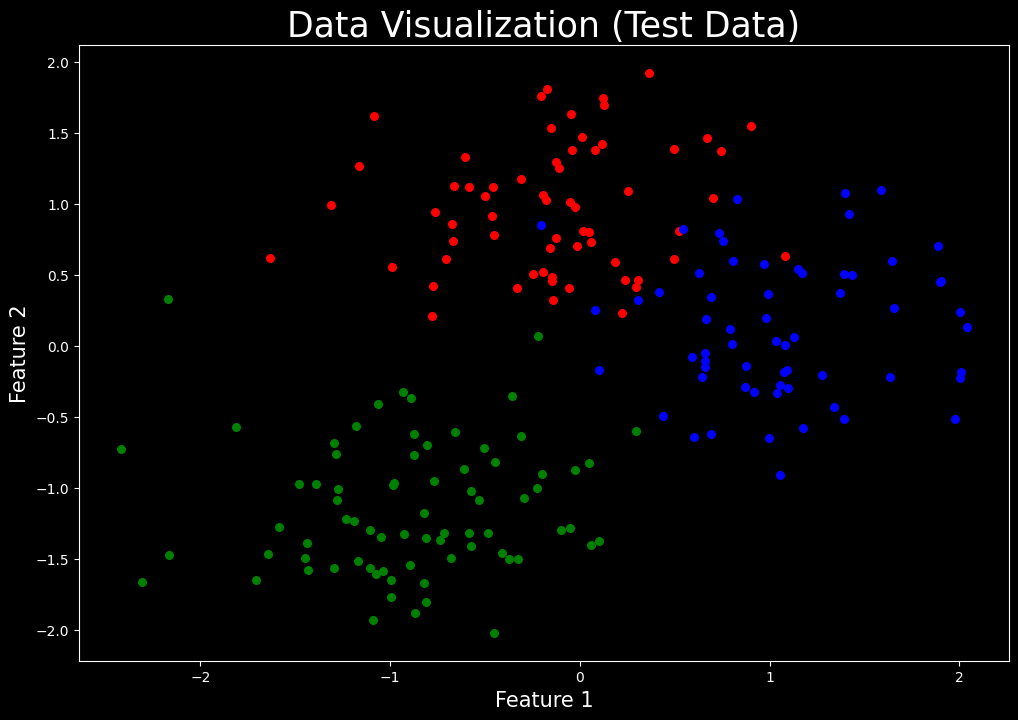

In [ ]:
plt.figure(figsize = (12,8))
plt.scatter(X_test_scaled[y_test == 0, 0], X_test_scaled[y_test == 0, 1], s = 30, c = 'red')
plt.scatter(X_test_scaled[y_test == 1, 0], X_test_scaled[y_test == 1, 1], s = 30, c = 'blue')
plt.scatter(X_test_scaled[y_test == 2, 0], X_test_scaled[y_test == 2, 1], s = 30, c = 'green')
plt.xlabel('Feature 1', fontsize = 15)
plt.ylabel('Feature 2', fontsize = 15)
plt.title('Data Visualization (Test Data)', fontsize = 25)
plt.show()

# Applying KNN Classifier

In [ ]:
knn = KNeighborsClassifier()

In [ ]:
#help(KNeighborsClassifier)

# Training the model and Predicting the test data

In [ ]:
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)

In [ ]:
Accuracy = np.mean(y_pred == y_test) * 100
print("Accuracy : %2.2f" % (Accuracy))

Accuracy : 92.50


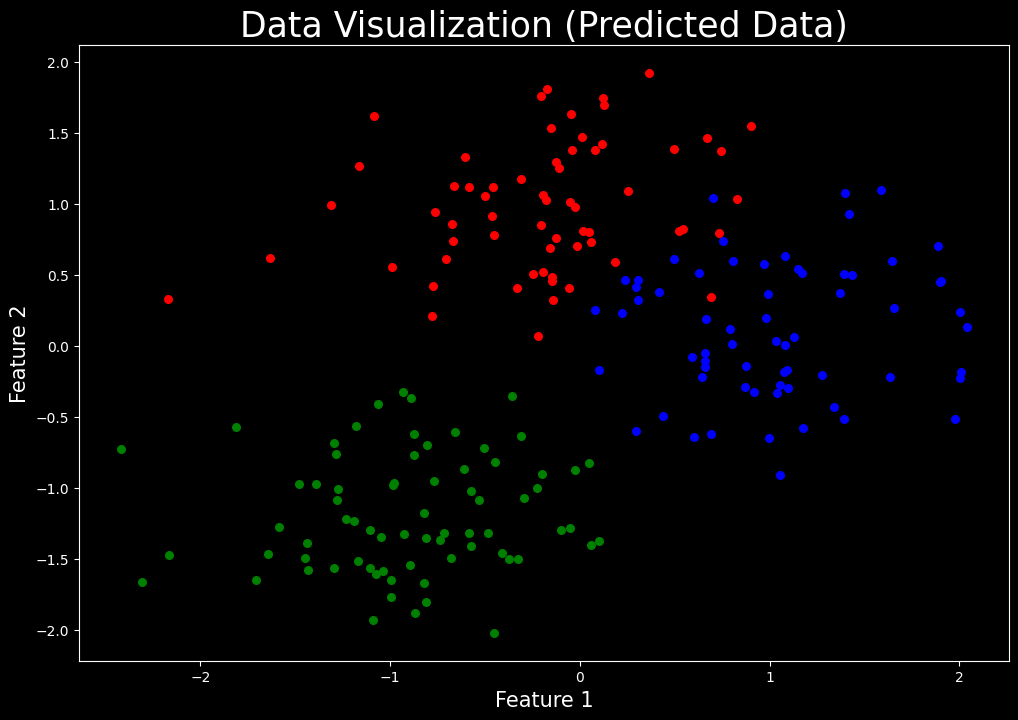

In [ ]:
plt.figure(figsize = (12,8))
plt.scatter(X_test_scaled[y_pred == 0, 0], X_test_scaled[y_pred == 0, 1], s = 30, c = 'red')
plt.scatter(X_test_scaled[y_pred == 1, 0], X_test_scaled[y_pred == 1, 1], s = 30, c = 'blue')
plt.scatter(X_test_scaled[y_pred == 2, 0], X_test_scaled[y_pred == 2, 1], s = 30, c = 'green')
plt.xlabel('Feature 1', fontsize = 15)
plt.ylabel('Feature 2', fontsize = 15)
plt.title('Data Visualization (Predicted Data)', fontsize = 25)
plt.show()

# Finding Optimal Value of k Using Error Rate plot

In [ ]:
Error_Rate = []

for i in range(1,30):

    knn_opt = KNeighborsClassifier(n_neighbors = i)#crea modelo KNN usando i vecinos
    knn_opt.fit(X_train_scaled,y_train) #entrena modelo con datos entrenamiento ya escalados
    y_pred_opt = knn_opt.predict(X_test_scaled) #hace predicciones sobre conjunto test
    Accuracy = np.mean(y_pred_opt == y_test) # Calcula la precisión como el porcentaje de aciertos.
    error_rate_value = 1 - Accuracy #Convierte la precisión en tasa de error
    Error_Rate.append(error_rate_value)#Añade el valor de error calculado (error_rate_value) a la lista Error_Rate.
    #ir guardando errores en cada valor de k, para graficarlos como varia el error según nº de vecinos

Text(0, 0.5, 'Error Rate')

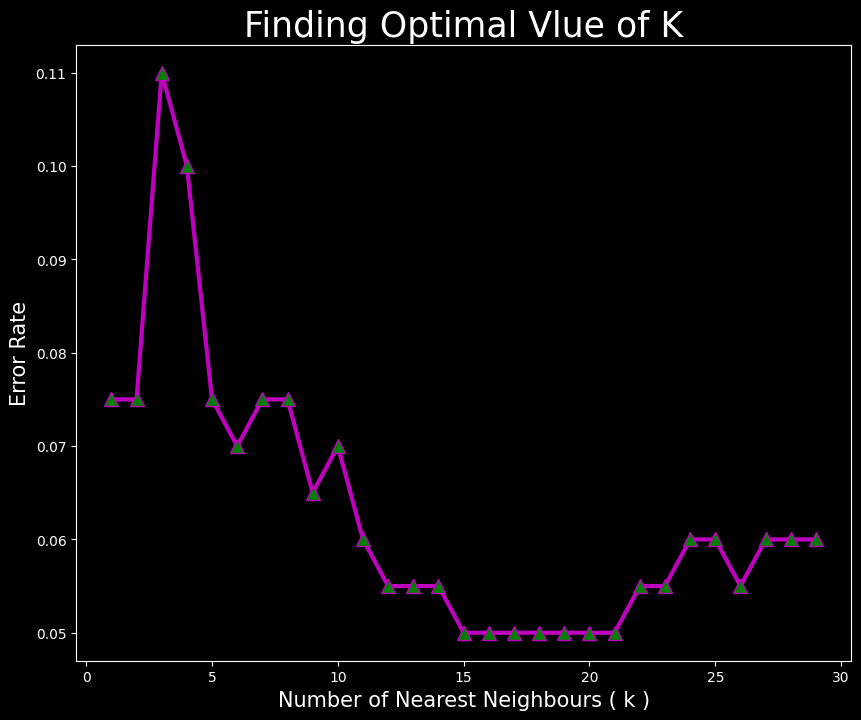

In [ ]:
plt.figure(figsize=(10,8))
plt.plot(range(1, 30), Error_Rate, 'm', lw = 3,  marker ='^', markerfacecolor ='g', markersize = 10)
plt.title('Finding Optimal Vlue of K', fontsize = 25)
plt.xlabel('Number of Nearest Neighbours ( k )', fontsize = 15)
plt.ylabel('Error Rate', fontsize = 15)

In [ ]:
knn_15 = KNeighborsClassifier(n_neighbors = 15)

In [ ]:
knn_15.fit(X_train_scaled, y_train)
y_pred_15 = knn_15.predict(X_test_scaled)

In [ ]:
Accuracy = np.mean(y_pred_15 == y_test) * 100
print("Accuracy : %2.2f" % (Accuracy))

Accuracy : 95.00


# Find the Value of k Using GridsearchCV Method

In [ ]:
k = 5
cv = KFold(n_splits=k, random_state = 42 , shuffle=True)#shuffle-> mezclar
#el modelo entrena con datos train, y predice con datos test y calcula el error con datos test
#escala con ambos pero no hace fit(aprende) de datos test-> fuga de datos

In [ ]:
model = KNeighborsClassifier()
params_KNN = {'n_neighbors': list(np.arange(1,30))}
KNN_GS = GridSearchCV(model, param_grid = params_KNN, cv = cv)
KNN_GSCV = KNN_GS.fit(X_train_scaled, y_train)
KNN_GSCV.best_params_

{'n_neighbors': 25}

In [ ]:
y_pred_cv = KNN_GSCV.predict(X_test_scaled)

In [ ]:
Accuracy = np.mean(y_pred_cv == y_test) * 100
print("Accuracy : %2.2f" % (Accuracy))

Accuracy : 94.00


# Creating Confusion Matrix ( Accuracy = 95%)

In [ ]:
font = {
    'weight' : 'bold',
    'size'   : 15}
plt.rc('font', **font)

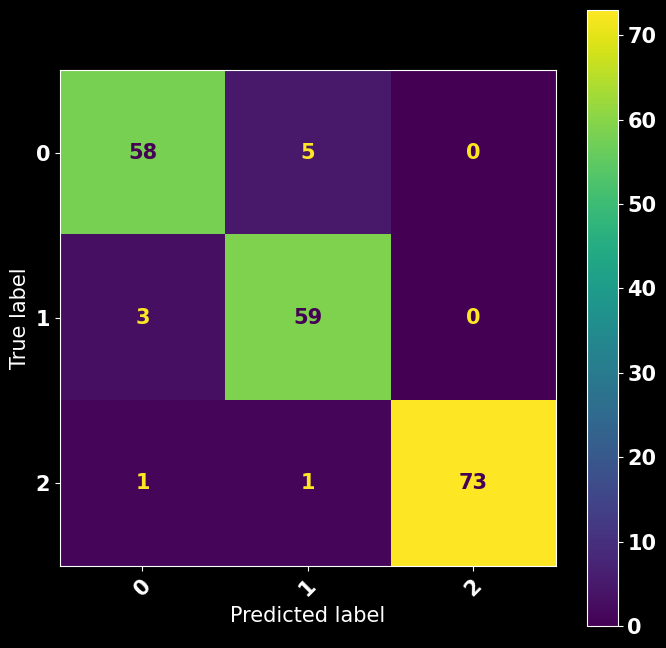

In [ ]:
from sklearn.metrics import confusion_matrix,f1_score,precision_score, recall_score, accuracy_score, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_15)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels= [0, 1, 2])
disp.plot(xticks_rotation=45)
fig = disp.ax_.get_figure()
fig.set_figwidth(8)
fig.set_figheight(8)
plt.show()

# Calculating Accuracy, Precision, Recall and F1-Score

In [ ]:
Accuracy = accuracy_score(y_test, y_pred_15, normalize=True).round(3)
Precision = precision_score(y_test, y_pred_15, average = 'macro').round(3)   # macro calculate the average value of classes.
Recall = recall_score(y_test, y_pred_15, average = 'macro').round(3)
F1_Score = f1_score(y_test, y_pred_15, average = 'macro').round(3)

print('Accuracy : ', Accuracy)
print(" ")
print('Precision : ', Precision)
print(" ")
print('Recall : ', Recall)
print(" ")
print('F1_Score : ', F1_Score)
print(" ")


Accuracy :  0.95
 
Precision :  0.948
 
Recall :  0.949
 
F1_Score :  0.948
 
